# Projeto Integrador: pipeline de dados para previsão de churn

**Disciplina:** Engenharia de Dados | **Autora:** Lorena (@Lorenalgm) | **Repositório:** https://github.com/Lorenalgm/projeto-integrador-engenharia-dados

**Problema.** Uma loja de artigos esportivos quer saber quais clientes vão parar de comprar, para agir antes
(cupom, contato, frete grátis). É um problema de **classificação**: para cada cliente ativo, prever se ele dará
churn nos próximos 90 dias.

**Fluxo.** Este notebook executa o pipeline de ponta a ponta, chamando os módulos de `src/`:

```
Fontes de dados  ->  PostgreSQL  ->  ETL Python  ->  Features  ->  Machine Learning  ->  Métricas  ->  Resultados
 CSV, Excel, JSON     staging         extract          29 por         3 modelos +         F1, recall,    modelo .pkl e
 API IBGE, Kaggle     dw (estrela)    transform        cliente        baseline            ROC AUC        tabelas em ml
                      ml              load
```

O mesmo fluxo roda pelo terminal com `python -m src.pipeline`. A análise exploratória está em
`01_analise_exploratoria.ipynb`.

Sequência:
1. Coleta: cinco fontes de dados
2. Transformação: limpeza e integração
3. Carga e modelagem no PostgreSQL
4. Engenharia de features
5. Treinamento e comparação dos modelos
6. Avaliação do modelo escolhido
7. O que as fontes externas acrescentam
8. Modelo salvo e resultados no banco
9. Conclusões

In [1]:
import logging
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))   # para importar o pacote src a partir da pasta notebooks/

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from src import config, extract, features, load, model, transform
from src.graficos import AZUL, CINZA, LARANJA, TEXTO, VERDE, configurar, rotular, salvar

warnings.filterwarnings('ignore', category=FutureWarning)
logging.getLogger('pipeline').setLevel(logging.WARNING)   # os números aparecem nas tabelas do notebook
configurar()
CORES = {'Regressão Logística': AZUL, 'Random Forest': LARANJA, 'Gradient Boosting': VERDE, model.BASELINE: CINZA}
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:.3f}')
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.12.9 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Coleta: cinco fontes de dados

| # | Fonte | Formato | Conteúdo | Origem |
|---|---|---|---|---|
| 1 | Sistema de vendas | CSV | uma linha por compra | fictícia (`src/gerar_dados.py`, semente fixa) |
| 2 | CRM | Excel | cadastro de clientes | fictícia |
| 3 | Catálogo | JSON aninhado | produtos por categoria, com preço e custo | fictícia |
| 4 | API de Localidades do IBGE | API REST | município, UF e região | real, consultada na hora |
| 5 | Kaggle `crisparada/brazilian-cities` | CSV via API do Kaggle | população, IDHM e PIB per capita | real (CC BY-SA 4.0) |

As três primeiras simulam os sistemas internos da loja e chegam sujas de propósito. As duas últimas são dados
públicos reais e servem para enriquecer o cadastro: a planilha só tem o nome da cidade.
`extract.extrair()` lê tudo como texto, sem tratar nada.

In [2]:
fontes = extract.extrair()
pd.DataFrame([{'fonte': nome, 'linhas': len(df), 'colunas': df.shape[1], 'nulos': int(df.isna().sum().sum()),
               'linhas repetidas': int(df.duplicated().sum())} for nome, df in fontes.items()])

,fonte,linhas,colunas,nulos,linhas repetidas
0,compras,17592,8,765,512
1,clientes,1545,8,185,45
2,produtos,25,5,0,0
3,municipios_ibge,5571,16,4,0
4,cidades_kaggle,5573,7,22,0


In [3]:
fontes['compras'].head(4)

,id_compra,cliente_id,produto_id,data_compra,quantidade,valor,canal,pagamento
0,16801,1155,P023,2026-06-19,1,363.55,App,Pix
1,11370,86,P001,2026-01-03,1,279.44,Loja Física,Pix
2,13872,432,P008,2026-03-15,1,104.26,App,Cartão de Débito
3,5013,878,P001,2025-06-20,1,254.78,Site,Pix


In [4]:
fontes['clientes'].head(4)

,cliente_id,nome,email,data_nascimento,cidade,uf,segmento,data_cadastro
0,1496,Mariana Alves,cliente1496@email.com,2003-06-10,São Paulo,SP,Bronze,2024-05-26
1,544,Daniel Monteiro,cliente0544@email.com,2004-07-17,Vitória,ES,Bronze,2025-12-06
2,1269,Leonardo Góes,cliente1269@email.com,1991-03-31,Brasília,DF,Bronze,2026-02-01
3,529,Carla Souza,cliente0529@email.com,1972-03-20,Recife,PE,Ouro,2025-01-29


In [5]:
fontes['produtos'].head(3)

,produto_id,nome,preco,custo,categoria
0,P001,Chuteira Society,289.9,143.81,Futebol
1,P002,Bola de Campo Oficial,159.9,71.98,Futebol
2,P003,Camisa de Time,249.9,114.53,Futebol


In [6]:
fontes['municipios_ibge'][['municipio-id', 'municipio-nome', 'UF-sigla', 'UF-nome', 'regiao-nome']].head(3)

,municipio-id,municipio-nome,UF-sigla,UF-nome,regiao-nome
0,1100015,Alta Floresta D'Oeste,RO,Rondônia,Norte
1,1100023,Ariquemes,RO,Rondônia,Norte
2,1100031,Cabixi,RO,Rondônia,Norte


In [7]:
fontes['cidades_kaggle'].head(3)

,CITY,STATE,CAPITAL,IBGE_RES_POP,IDHM,ESTIMATED_POP,GDP_CAPITA
0,Abadia De Goiás,GO,0,6876,0.708,8583,20664.57
1,Abadia Dos Dourados,MG,0,6704,0.69,6972,25591.7
2,Abadiânia,GO,0,15757,0.69,19614,15628.4


## 2. Transformação: limpeza e integração

`transform.transformar()` limpa cada fonte e monta as tabelas do modelo estrela. Decisões técnicas:

- **Texto.** Caixa, espaços e acentos são normalizados antes de comparar (`'  OURO '` e `'ouro'` viram `'Ouro'`).
- **Datas e valores.** Aceita `AAAA-MM-DD` e `DD/MM/AAAA`, `1299.90` e `R$ 1.299,90`. Data impossível vira nula.
- **Duplicatas de clientes.** O mesmo `cliente_id` aparece mais de uma vez na planilha; fica a linha mais completa.
- **Integridade referencial.** Compra de cliente fora do cadastro ou de produto fora do catálogo é removida,
  porque não teria para onde apontar no modelo estrela.
- **Outliers.** O preço unitário pago é comparado com o preço de tabela do próprio produto (aceito de 50% a 110%).
  Um limite estatístico único para `valor` trataria produto caro como erro.
- **Essenciais.** Compra sem cliente, sem data ou sem valor é removida, não preenchida.
- **Não essenciais.** Nascimento inválido e cidade ausente ficam **nulos** no banco. Quem decide como preencher
  é o Pipeline do modelo, que calcula a mediana só com o treino.
- **Integração.** Cidade + UF do cliente viram o código do município do IBGE. Os indicadores do Kaggle entram
  pela mesma chave (nome + UF sem acento), porque o dataset não traz o código do IBGE.

Cada etapa registra quantas linhas entraram, quantas removeu e quantas restaram.

In [8]:
tabelas, etapas = transform.transformar(fontes)
etapas

,fonte,etapa,entraram,removidos,restaram,descricao
0,localidades,municípios do IBGE,5571,0,5571,Remove município sem UF ou região na resposta da API
1,localidades,indicadores do Kaggle,5571,0,5571,"Junção por nome + UF: 5551 municípios com IDHM, 20 ficam sem indicador"
2,produtos,catálogo válido,25,0,25,Achata o JSON e remove produto repetido ou sem preço e custo
3,clientes,sem duplicatas,1545,45,1500,Mantém uma linha por cliente_id (a mais completa)
4,clientes,sem inválidos,1500,0,1500,"Remove cliente sem id, nome, segmento ou data de cadastro válida"
5,clientes,município do IBGE,1500,0,1500,Troca cidade + UF pelo código do IBGE: 45 clientes sem cidade ficam com localidade nula
6,compras,sem duplicatas,17592,512,17080,Remove linhas repetidas
7,compras,sem inválidos,17080,732,16348,"Remove compra sem cliente, data ou valor, com data impossível ou futura, valor negativo ou quantidade fora de 1 a 20"
8,compras,integridade referencial,16348,99,16249,Remove compra de cliente fora do cadastro ou de produto fora do catálogo
9,compras,sem outliers de preço,16249,157,16092,Remove compra com preço unitário fora de 50% a 110% do preço de tabela


In [9]:
pd.DataFrame([{'tabela': nome, 'linhas': len(df), 'colunas': ', '.join(df.columns)} for nome, df in tabelas.items()])

,tabela,linhas,colunas
0,dim_localidade,5571,"codigo_ibge, municipio, uf, estado, regiao, capital, populacao, idhm, pib_per_capita"
1,dim_cliente,1500,"cliente_id, nome, email, data_nascimento, segmento, data_cadastro, codigo_ibge"
2,dim_produto,25,"produto_id, nome, categoria, preco, custo"
3,dim_data,545,"data, ano, trimestre, mes, nome_mes, dia_semana, nome_dia, fim_de_semana"
4,fato_compras,16092,"id_compra, cliente_id, produto_id, data_compra, quantidade, valor, custo_total, canal, pagamento"


## 3. Carga e modelagem no PostgreSQL

`sql/schema.sql` cria três schemas:

- **`staging`**: cada fonte como chegou, em texto. Permite auditar o que a limpeza rejeitou.
- **`dw`**: modelo estrela. `fato_compras` no centro, ligada a `dim_cliente`, `dim_produto` e `dim_data`;
  `dim_cliente` aponta para `dim_localidade` (IBGE + Kaggle). Chaves primárias e estrangeiras, `CHECK` nas regras
  de negócio e índices nas chaves do fato.
- **`ml`**: features por cliente, métricas dos modelos e previsões do teste.

A carga é completa (recria tudo) e as tabelas do `dw` entram em uma única transação: ou tudo, ou nada.

In [10]:
engine = load.conectar()
load.criar_estrutura(engine)
load.carregar_staging(engine, fontes)
load.carregar_dw(engine, tabelas, etapas)
load.verificar(engine, tabelas)   # confere contagens, receita e junções direto no banco
ler = lambda sql: load.ler(engine, sql)
print('Banco:', engine.url.render_as_string(hide_password=True))

ler("""
    SELECT table_schema AS schema, table_name AS tabela,
           (xpath('/row/n/text()', query_to_xml(format('SELECT count(*) AS n FROM %I.%I', table_schema, table_name), false, true, '')))[1]::text::int AS linhas
    FROM information_schema.tables
    WHERE table_schema IN ('staging', 'dw') AND table_type = 'BASE TABLE'
    ORDER BY table_schema DESC, table_name
""")

Banco: postgresql+psycopg2://localhost/projeto_integrador


,schema,tabela,linhas
0,staging,cidades_kaggle,5573
1,staging,clientes,1545
2,staging,compras,17592
3,staging,municipios_ibge,5571
4,staging,produtos,25
5,dw,dim_cliente,1500
6,dw,dim_data,545
7,dw,dim_localidade,5571
8,dw,dim_produto,25
9,dw,etl_etapas,10


Conferência de qualidade com SQL (as mesmas consultas estão em `sql/verificacao.sql`):

In [11]:
ler("""
    SELECT (SELECT count(*) FROM dw.fato_compras) AS compras,
           (SELECT count(*) - count(DISTINCT id_compra) FROM dw.fato_compras) AS ids_repetidos,
           (SELECT count(*) FROM dw.fato_compras f LEFT JOIN dw.dim_cliente c USING (cliente_id) WHERE c.cliente_id IS NULL) AS compras_sem_cliente,
           (SELECT count(*) FROM dw.fato_compras f LEFT JOIN dw.dim_produto p USING (produto_id) WHERE p.produto_id IS NULL) AS compras_sem_produto,
           (SELECT count(*) FROM dw.fato_compras WHERE data_compra > DATE '2026-06-30') AS datas_futuras,
           (SELECT count(*) FROM dw.fato_compras WHERE valor <= 0 OR quantidade NOT BETWEEN 1 AND 20) AS valores_invalidos
""")

,compras,ids_repetidos,compras_sem_cliente,compras_sem_produto,datas_futuras,valores_invalidos
0,16092,0,0,0,0,0


Uma consulta analítica que só é possível com as fontes integradas: receita e margem por região
(compra do CSV, custo do JSON, cliente do Excel, região da API do IBGE, IDHM do Kaggle).

In [12]:
ler("""
    SELECT coalesce(regiao, 'Sem cidade') AS regiao, count(DISTINCT cliente_id) AS clientes, count(*) AS compras,
           round(sum(valor), 2)::float AS receita, round(100 * sum(margem) / sum(valor), 1)::float AS margem_pct,
           round(avg(idhm), 3)::float AS idhm_medio
    FROM dw.vw_compras GROUP BY 1 ORDER BY receita DESC
""")

,regiao,clientes,compras,receita,margem_pct,idhm_medio
0,Norte,599,7222,4325580.150,35.800,0.731
1,Nordeste,268,2971,1759656.800,36.100,0.760
2,Sudeste,282,3048,1706794.260,35.400,0.806
3,Centro-Oeste,121,1419,822990.160,34.900,0.804
4,Sul,106,965,488193.780,35.500,0.818
5,Sem cidade,43,467,295765.620,36.200,NaN


## 4. Engenharia de features

As features são calculadas a partir da visão `dw.vw_compras`, lida do PostgreSQL.

- **Target.** `churn = 1` se o cliente não comprou nos 90 dias depois da data de corte (31/03/2026).
- **Sem vazamento.** As features usam somente as compras até o corte. Se o churn fosse definido como
  "mais de 90 dias sem comprar" e essa mesma coluna entrasse como feature, o modelo acertaria tudo sem prever nada.
- **Base.** Clientes ativos, com pelo menos uma compra nos 180 dias antes do corte.
- **Nulos.** Idade e indicadores de cidade podem faltar; a imputação pela mediana fica dentro do Pipeline do modelo.
- **Escala.** A padronização (`StandardScaler`) também fica dentro do Pipeline, ajustada só no treino.

In [13]:
X, y, clientes = features.preparar(engine)    # também grava ml.features_cliente
X_train, X_test, y_train, y_test = model.dividir(X, y)

print(f'Clientes: {len(X)} | features: {X.shape[1]} | churn: {y.mean():.1%}')
print(f'Treino: {len(X_train)} ({y_train.mean():.1%} de churn) | Teste: {len(X_test)} ({y_test.mean():.1%} de churn)')
print(f'Features com valor ausente: {X.isna().sum()[lambda s: s > 0].to_dict()}')
X.head(4)

Clientes: 999 | features: 29 | churn: 30.8%
Treino: 799 (30.8% de churn) | Teste: 200 (31.0% de churn)
Features com valor ausente: {'capital': 33, 'idhm': 33, 'pib_per_capita': 33, 'idade': 52, 'populacao_log': 33}


,capital,idhm,pib_per_capita,idade,dias_desde_cadastro,dias_sem_comprar,intervalo_medio_dias,atraso_relativo,pct_compras_fim_de_semana,qtd_compras,total_gasto,ticket_medio,categorias_distintas,margem_pct,pct_compras_online,qtd_compras_90d,gasto_90d,tendencia_compras,compras_por_mes,segmento_cod,canal_Loja Física,canal_Site,canal_App,regiao_Norte,regiao_Nordeste,regiao_Centro-Oeste,regiao_Sudeste,regiao_Sul,populacao_log
cliente_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2,1.000,0.820,79099.770,47.800,219.000,68.000,20.286,3.352,0.500,8.000,2427.760,303.470,4.000,0.333,1.000,1.000,23.800,-3.000,1.137,1.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,6.473
4,1.000,0.805,57071.430,52.500,103.000,102.000,102.000,1.000,0.000,1.000,87.060,87.060,1.000,0.257,1.000,0.000,0.000,-1.000,0.291,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,7.086
6,1.000,0.763,23345.930,35.400,231.000,24.000,15.154,1.584,0.357,14.000,3677.210,262.658,4.000,0.407,0.214,5.000,1482.070,0.000,1.892,2.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,5.903
7,1.000,0.759,20796.620,42.400,71.000,31.000,9.000,3.444,0.500,2.000,2647.710,1323.855,2.000,0.239,0.500,2.000,2647.710,2.000,1.463,1.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,0.000,6.456


Documentação de cada feature (também gravada em `reports/documentacao_features.csv`):

In [14]:
doc = features.documentacao()
doc.to_csv(config.RESULTADOS / 'documentacao_features.csv', index=False)
doc.style.hide(axis='index').set_properties(**{'text-align': 'left', 'font-size': '9pt'})

feature,grupo,fonte,como é calculada,o que representa e por que ajuda
idade,Cadastro,Excel,Anos entre data_nascimento e a data de corte,Clientes mais jovens trocam de loja com mais facilidade. Fica nula quando o nascimento é inválido
segmento_cod,Cadastro,Excel,"Bronze = 0, Prata = 1, Ouro = 2 (encoding ordinal)","Nível no programa de fidelidade. Tem ordem, por isso vira um número só"
dias_desde_cadastro,Temporal,Excel,Dias entre data_cadastro e a data de corte,Tempo de relacionamento com a loja
dias_sem_comprar,Temporal,CSV,Dias entre a última compra e a data de corte,"Recência: quanto mais tempo parado, maior a chance de já ter abandonado"
intervalo_medio_dias,Temporal,CSV,"Dias entre a primeira e a última compra, dividido por (compras - 1)","Ritmo normal do cliente. Com uma compra só, usa os dias desde essa compra"
atraso_relativo,Temporal,CSV,dias_sem_comprar / intervalo_medio_dias,Compara a pausa atual com o ritmo do próprio cliente: 60 dias parado é normal para uns e alarme para outros
pct_compras_fim_de_semana,Temporal,CSV + dim_data,Parcela das compras feitas em sábado ou domingo,Hábito de compra (lazer no fim de semana ou rotina durante a semana)
qtd_compras,Agregação,CSV,Número de compras até o corte,Frequência: volume de relacionamento
total_gasto,Agregação,CSV,Soma do valor das compras até o corte,Valor monetário do cliente
ticket_medio,Agregação,CSV,total_gasto / qtd_compras,Tamanho típico de cada compra


## 5. Treinamento e comparação dos modelos

Três modelos de famílias diferentes e um baseline que sempre responde "não é churn" (serve de piso).

| Modelo | Configuração | Por que testar |
|---|---|---|
| Regressão Logística | `class_weight='balanced'` | Linear, simples e fácil de interpretar |
| Random Forest | 300 árvores, `min_samples_leaf=5`, `class_weight='balanced'` | Capta relações não lineares e interações |
| Gradient Boosting | 100 árvores (padrão do scikit-learn) | Árvores em sequência, cada uma corrigindo a anterior |

Todos ficam em um `Pipeline` (imputação pela mediana, padronização e classificador). `class_weight='balanced'`
compensa o desbalanceamento, dando mais peso aos erros na classe churn. A validação cruzada (5 dobras
estratificadas) roda só no treino; o teste fica guardado para a avaliação final.

In [15]:
comparacao, modelos, previsoes = model.treinar_e_comparar(X_train, y_train, X_test, y_test)
for nome in modelos:
    print(f'{"=" * 56}\n{nome}')
    print(classification_report(y_test, previsoes[nome][0], target_names=['ficou', 'churn'], zero_division=0))

Baseline (classe majoritária)
              precision    recall  f1-score   support

       ficou       0.69      1.00      0.82       138
       churn       0.00      0.00      0.00        62

    accuracy                           0.69       200
   macro avg       0.34      0.50      0.41       200
weighted avg       0.48      0.69      0.56       200

Regressão Logística
              precision    recall  f1-score   support

       ficou       0.84      0.85      0.84       138
       churn       0.66      0.65      0.65        62

    accuracy                           0.79       200
   macro avg       0.75      0.75      0.75       200
weighted avg       0.78      0.79      0.78       200

Random Forest
              precision    recall  f1-score   support

       ficou       0.80      0.91      0.85       138
       churn       0.72      0.50      0.59        62

    accuracy                           0.79       200
   macro avg       0.76      0.71      0.72       200
weighted a

Métricas usadas e o que cada uma responde, sempre para a classe churn:
- **accuracy**: de todos os clientes, quantos o modelo classificou certo. Engana com classes desbalanceadas.
- **precision**: dos clientes que o modelo apontou como churn, quantos realmente saíram.
- **recall**: dos clientes que realmente saíram, quantos o modelo encontrou.
- **F1**: média harmônica de precision e recall. É a métrica principal aqui.
- **ROC AUC**: qualidade do ranking de risco, independente do ponto de corte (0,5 é aleatório, 1,0 é perfeito).

As colunas `cv_` são a média das 5 dobras no treino; as demais são do conjunto de teste.

In [16]:
comparacao

,modelo,escolhido,cv_f1,cv_f1_desvio,cv_roc_auc,accuracy,precision,recall,f1,roc_auc
0,Regressão Logística,True,0.601,0.043,0.777,0.785,0.656,0.645,0.650,0.790
1,Random Forest,False,0.599,0.050,0.778,0.785,0.721,0.500,0.590,0.789
2,Gradient Boosting,False,0.555,0.058,0.755,0.760,0.750,0.339,0.467,0.728
3,Baseline (classe majoritária),False,0.000,0.000,0.500,0.690,0.000,0.000,0.000,0.500


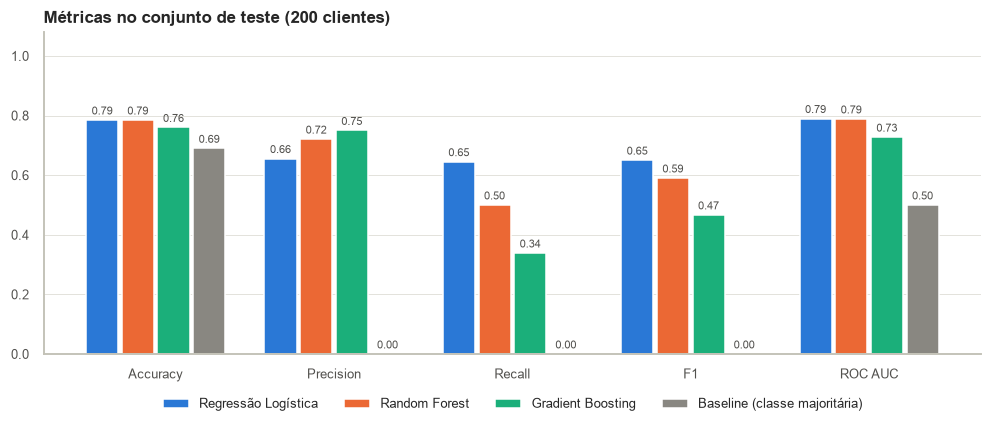

In [17]:
ordem = [m for m in CORES if m in modelos]
fig, ax = plt.subplots(figsize=(11, 3.8))
largura = 0.2
for i, nome in enumerate(ordem):
    valores = comparacao.set_index('modelo').loc[nome, model.METRICAS].astype(float)
    barras = ax.bar(np.arange(len(model.METRICAS)) + (i - 1.5) * largura, valores, width=largura - 0.02, color=CORES[nome], label=nome)
    ax.bar_label(barras, fmt='%.2f', padding=2, fontsize=7.5, color=TEXTO)
ax.set_xticks(np.arange(len(model.METRICAS)), ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC'])
ax.set(title=f'Métricas no conjunto de teste ({len(y_test)} clientes)', ylim=(0, 1.08))
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=8.5)
salvar(fig, '09_comparacao_modelos.png')

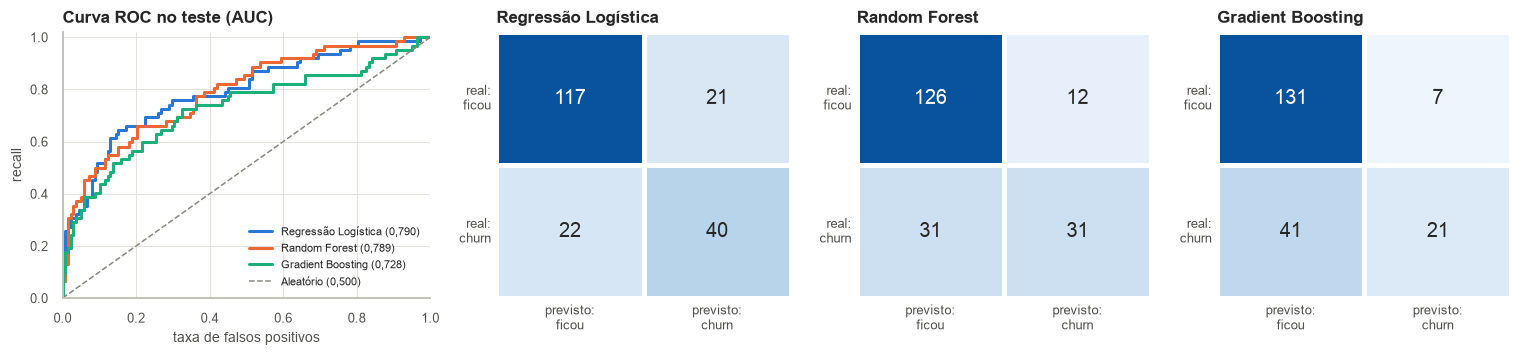

In [18]:
fig, eixos = plt.subplots(1, 4, figsize=(14, 3.4), gridspec_kw={'width_ratios': [1.25, 1, 1, 1]})
for nome in ordem[:3]:
    fpr, tpr, _ = roc_curve(y_test, previsoes[nome][1])
    eixos[0].plot(fpr, tpr, color=CORES[nome], linewidth=2, label=f'{nome} ({roc_auc_score(y_test, previsoes[nome][1]):.3f})'.replace('.', ','))
eixos[0].plot([0, 1], [0, 1], color=CINZA, linewidth=1, linestyle='--', label='Aleatório (0,500)')
eixos[0].set(title='Curva ROC no teste (AUC)', xlabel='taxa de falsos positivos', ylabel='recall', xlim=(0, 1), ylim=(0, 1.02))
eixos[0].legend(loc='lower right', frameon=False, fontsize=7.5)
for ax, nome in zip(eixos[1:], ordem[:3]):
    mc = confusion_matrix(y_test, previsoes[nome][0])
    sns.heatmap(mc, annot=True, fmt='d', cmap='Blues', cbar=False, vmin=0, vmax=mc.max() * 1.15, linewidths=2, linecolor='white',
                annot_kws={'size': 13}, xticklabels=['previsto:\nficou', 'previsto:\nchurn'], yticklabels=['real:\nficou', 'real:\nchurn'], ax=ax)
    ax.set_title(nome)
    ax.tick_params(length=0)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
salvar(fig, '10_roc_e_matrizes.png')

## 6. Avaliação do modelo escolhido

O critério é o **F1 médio na validação cruzada**, calculado só com o treino. Escolher pelo resultado do teste
usaria o teste duas vezes, para escolher e para avaliar, e a métrica final ficaria otimista.

In [19]:
melhor_nome = model.escolher(comparacao)
melhor = modelos[melhor_nome]
vencedor, segundo = (comparacao[comparacao['modelo'] != model.BASELINE].iloc[i] for i in (0, 1))
y_pred, y_prob = previsoes[melhor_nome]
print(f'Modelo escolhido: {melhor_nome}')
print(f'F1 na validação cruzada: {vencedor["cv_f1"]:.3f} (desvio {vencedor["cv_f1_desvio"]:.3f}) | segundo colocado: {segundo["modelo"]} com {segundo["cv_f1"]:.3f}')
print(f'No teste: F1 {vencedor["f1"]:.3f} | recall {vencedor["recall"]:.3f} | precision {vencedor["precision"]:.3f} | ROC AUC {vencedor["roc_auc"]:.3f} | accuracy {vencedor["accuracy"]:.3f}')

Modelo escolhido: Regressão Logística
F1 na validação cruzada: 0.601 (desvio 0.043) | segundo colocado: Random Forest com 0.599
No teste: F1 0.650 | recall 0.645 | precision 0.656 | ROC AUC 0.790 | accuracy 0.785


### Importância das features
Importância por permutação no teste: embaralha uma coluna por vez e mede quanto o ROC AUC cai. Quanto maior a
queda, mais o modelo depende daquela feature. A linha fina é o desvio padrão em 30 repetições.

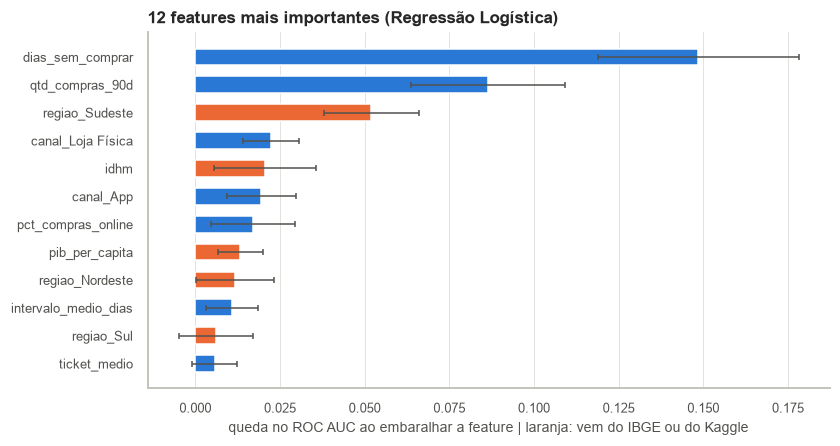

,importancia,desvio
feature,,
dias_sem_comprar,0.149,0.029
qtd_compras_90d,0.086,0.023
regiao_Sudeste,0.052,0.014
canal_Loja Física,0.022,0.008
idhm,0.021,0.015
canal_App,0.019,0.010
pct_compras_online,0.017,0.012
pib_per_capita,0.013,0.007
regiao_Nordeste,0.012,0.011


In [20]:
imp = model.importancia(melhor, X_test, y_test)
externas = features.colunas_de_localidade(X)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top['importancia'], xerr=top['desvio'], color=[LARANJA if f in externas else AZUL for f in top.index], height=0.6,
        error_kw={'ecolor': TEXTO, 'elinewidth': 1, 'capsize': 2})
ax.set(title=f'12 features mais importantes ({melhor_nome})', xlabel='queda no ROC AUC ao embaralhar a feature | laranja: vem do IBGE ou do Kaggle')
ax.grid(axis='y', visible=False)
salvar(fig, '11_importancia_features.png')
imp.head(12).round(4)

### Faixas de risco
Na prática o time de retenção não usa só "churn / não churn": usa a probabilidade para priorizar. A tabela agrupa
os clientes do teste por faixa de probabilidade prevista e mostra quantos realmente saíram em cada uma.
Se o modelo ordena bem, a taxa real de churn sobe de uma faixa para a outra.

In [21]:
risco = pd.DataFrame({'risco': model.faixa_de_risco(y_prob), 'churn': y_test.values, 'prob': y_prob})
faixas = risco.groupby('risco', observed=True).agg(clientes=('churn', 'size'), deram_churn=('churn', 'sum'),
                                                  taxa_real_de_churn=('churn', 'mean'), probabilidade_media_prevista=('prob', 'mean'))
faixas['% dos churns do teste'] = faixas['deram_churn'] / faixas['deram_churn'].sum()
faixas

,clientes,deram_churn,taxa_real_de_churn,probabilidade_media_prevista,% dos churns do teste
risco,,,,,
baixo,115,17,0.148,0.218,0.274
médio,50,21,0.420,0.531,0.339
alto,35,24,0.686,0.851,0.387


### Ponto de corte
O padrão é classificar como churn quando a probabilidade passa de 0,5. Baixar o corte encontra mais churns
(recall maior) ao custo de mais alarmes falsos (precision menor). A escolha depende do custo da ação de retenção.

In [22]:
cortes = pd.DataFrame([{'corte': c, **{k: v for k, v in model.avaliar(y_test, (y_prob >= c).astype(int), y_prob).items() if k != 'roc_auc'},
                        'clientes acionados': int((y_prob >= c).sum())} for c in [0.3, 0.4, 0.5, 0.6, 0.7]])
cortes

,corte,accuracy,precision,recall,f1,clientes acionados
0,0.300,0.620,0.439,0.806,0.568,114
1,0.400,0.715,0.529,0.726,0.612,85
2,0.500,0.785,0.656,0.645,0.650,61
3,0.600,0.775,0.673,0.532,0.595,49
4,0.700,0.755,0.686,0.387,0.495,35


## 7. O que as fontes externas acrescentam

As features de localidade (região da API do IBGE; capital, população, IDHM e PIB per capita do Kaggle) só existem
por causa da integração. Para medir o que elas valem, o modelo escolhido é treinado de novo sem elas e comparado
na validação cruzada (mesmas dobras, só no treino).

In [23]:
conjuntos = {
    'Só fontes internas (CSV, Excel, JSON)': [c for c in X.columns if c not in externas],
    'Internas + região (API IBGE)': [c for c in X.columns if c not in externas or c.startswith('regiao_')],
    'Todas as fontes (com Kaggle)': list(X.columns),
}
ablacao = pd.DataFrame([{'features usadas': nome, 'quantidade': len(cols), **model.validacao_cruzada(model.candidatos()[melhor_nome], X_train[cols], y_train)}
                        for nome, cols in conjuntos.items()])
ablacao.to_csv(config.RESULTADOS / 'comparacao_fontes.csv', index=False)
ablacao

,features usadas,quantidade,cv_f1,cv_f1_desvio,cv_roc_auc
0,"Só fontes internas (CSV, Excel, JSON)",20,0.596,0.050,0.785
1,Internas + região (API IBGE),25,0.595,0.048,0.780
2,Todas as fontes (com Kaggle),29,0.601,0.043,0.777


## 8. Modelo salvo e resultados no banco

`model.salvar()` grava o `Pipeline` inteiro (imputação + padronização + classificador) em `models/modelo_churn.pkl`,
as métricas em `reports/` e, no PostgreSQL, `ml.metricas_modelo` e `ml.previsoes_teste`.

In [24]:
resumo = model.salvar(engine, comparacao, modelos, previsoes, imp, X_test, y_test)
carregado = joblib.load(model.CAMINHO_MODELO)
assert (carregado.predict(X_test) == y_pred).all() and list(carregado.feature_names_in_) == list(X.columns)
print(f'Modelo salvo: {model.CAMINHO_MODELO.relative_to(config.RAIZ)} ({model.CAMINHO_MODELO.stat().st_size / 1024:.0f} KB). Recarregado, devolve as mesmas previsões.')
resumo

Modelo salvo: models/modelo_churn.pkl (3 KB). Recarregado, devolve as mesmas previsões.


{'modelo': 'Regressão Logística',
 'data_de_corte': '2026-03-31',
 'clientes_no_teste': 200,
 'taxa_de_churn_no_teste': 0.31,
 'cv_f1': 0.601,
 'cv_roc_auc': 0.7773,
 'accuracy': 0.785,
 'precision': 0.6557,
 'recall': 0.6452,
 'f1': 0.6504,
 'roc_auc': 0.79}

In [25]:
ler('SELECT modelo, escolhido, cv_f1, accuracy, precision, recall, f1, roc_auc FROM ml.metricas_modelo ORDER BY cv_f1 DESC').astype({c: float for c in ['cv_f1', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']})

,modelo,escolhido,cv_f1,accuracy,precision,recall,f1,roc_auc
0,Regressão Logística,True,0.601,0.785,0.656,0.645,0.650,0.790
1,Random Forest,False,0.599,0.785,0.721,0.500,0.591,0.789
2,Gradient Boosting,False,0.555,0.760,0.750,0.339,0.467,0.728
3,Baseline (classe majoritária),False,0.000,0.690,0.000,0.000,0.000,0.500


Os 5 clientes do teste com maior risco previsto, com o que aconteceu de fato, consultados no banco:

In [26]:
ler("""
    SELECT p.cliente_id, c.segmento, l.municipio, l.uf, f.dias_sem_comprar::int, f.qtd_compras_90d::int,
           p.prob_churn, p.risco, p.churn_previsto, p.churn_real
    FROM ml.previsoes_teste p
    JOIN ml.features_cliente f USING (cliente_id)
    JOIN dw.dim_cliente c USING (cliente_id)
    LEFT JOIN dw.dim_localidade l USING (codigo_ibge)
    ORDER BY p.prob_churn DESC LIMIT 5
""")

,cliente_id,segmento,municipio,uf,dias_sem_comprar,qtd_compras_90d,prob_churn,risco,churn_previsto,churn_real
0,333,Bronze,Cuiabá,MT,136,0,0.965,alto,1,1
1,22,Bronze,Belo Horizonte,MG,147,0,0.960,alto,1,1
2,437,Bronze,Belém,PA,115,0,0.947,alto,1,1
3,1349,Bronze,Belo Horizonte,MG,151,0,0.944,alto,1,1
4,635,Bronze,João Pessoa,PB,162,0,0.941,alto,1,0


## 9. Conclusões

In [27]:
n = lambda v, casas=3: f'{v:.{casas}f}'.replace('.', ',')
mil = lambda v: f'{int(v):,}'.replace(',', '.')
base = comparacao.set_index('modelo').loc[model.BASELINE]
gb = comparacao.set_index('modelo').loc['Gradient Boosting']
mc = confusion_matrix(y_test, y_pred)
alto, baixo = faixas.loc['alto'], faixas.loc['baixo']
ab = ablacao.set_index('features usadas')
ganho_f1 = ab['cv_f1'].iloc[-1] - ab['cv_f1'].iloc[0]
ganho_auc = ab['cv_roc_auc'].iloc[-1] - ab['cv_roc_auc'].iloc[0]
top2 = ' e '.join(f'`{f}`' for f in imp.index[:2])
sinal = lambda v: ('+' if v >= 0 else '-') + n(abs(v))
ext_top = [f for f in imp.index[:12] if f in externas]
c40 = cortes.set_index('corte').loc[0.4]
Markdown(f"""
- **O pipeline roda de ponta a ponta.** Cinco fontes ({mil(len(fontes['compras']))} linhas de compras, {mil(len(fontes['clientes']))} de
  clientes, {len(fontes['produtos'])} produtos, {mil(len(fontes['municipios_ibge']))} municípios do IBGE e {mil(len(fontes['cidades_kaggle']))}
  do Kaggle) viram {mil(len(tabelas['fato_compras']))} compras limpas no modelo estrela do PostgreSQL, {X.shape[1]} features para
  {len(X)} clientes e um modelo salvo. Tudo é reproduzível: semente fixa e um único comando.
- **Modelo escolhido: {melhor_nome}.** Teve o maior F1 na validação cruzada ({n(vencedor['cv_f1'])}), praticamente empatada com
  {segundo['modelo']} ({n(segundo['cv_f1'])}; o desvio entre dobras é de {n(vencedor['cv_f1_desvio'])}). Entre dois modelos empatados,
  o mais simples e interpretável é a melhor escolha.
- **Quanto ele acerta.** No teste ({len(y_test)} clientes), F1 {n(vencedor['f1'])}, ROC AUC {n(vencedor['roc_auc'])} e accuracy
  {n(vencedor['accuracy'])}. Encontrou {mc[1, 1]} dos {mc[1].sum()} clientes que deram churn (recall {n(vencedor['recall'])}). Dos
  {mc[:, 1].sum()} que apontou como risco, {mc[1, 1]} realmente saíram (precision {n(vencedor['precision'])}).
- **Por que não olhar só a accuracy.** Responder sempre "não é churn" acerta {base['accuracy']:.0%} dos casos sem encontrar
  nenhum churn. O ganho real do modelo está no recall e no F1, não nos poucos pontos de accuracy acima do baseline.
- **O Gradient Boosting é mais cauteloso.** Sem balanceamento de classes, só alerta com muita certeza e deixa passar
  a maioria dos churns (recall {n(gb['recall'])}). Para retenção, perder um cliente custa mais do que um cupom a quem ia ficar.
- **O ranking de risco funciona.** Na faixa de risco alto, {alto['taxa_real_de_churn']:.0%} dos {int(alto['clientes'])} clientes realmente
  saíram; na faixa de risco baixo, {baixo['taxa_real_de_churn']:.0%} dos {int(baixo['clientes'])}. Com o corte em 0,4, o recall sobe para
  {n(c40['recall'])} com precision de {n(c40['precision'])}, acionando {int(c40['clientes acionados'])} clientes.
- **O que mais pesa.** {top2}, bem à frente das demais. Recência e atividade recente são os sinais
  mais fortes, como a análise exploratória indicava.
- **Fontes externas.** Com as features de localidade, o F1 da validação cruzada vai de {n(ab['cv_f1'].iloc[0])} para
  {n(ab['cv_f1'].iloc[-1])} ({sinal(ganho_f1)}) e o ROC AUC muda {sinal(ganho_auc)}. As duas diferenças são menores que o desvio entre
  dobras ({n(vencedor['cv_f1_desvio'])}), ou seja, **não há ganho mensurável na previsão**. O modelo até usa essas colunas quando
  elas existem ({', '.join(f'`{f}`' for f in ext_top[:3])} aparecem entre as 12 mais importantes), mas sem elas chega ao mesmo
  resultado: o comportamento de compra explica muito mais do que a cidade. O valor da integração ficou na análise
  (receita, margem e churn por região) e não no modelo.
- **Limitações.** As compras, os clientes e o catálogo são simulados, com premissas de abandono definidas em
  `src/gerar_dados.py` (segmento, canal, idade e região); só o IBGE e o Kaggle são dados reais. O abandono simulado
  tem um componente aleatório grande, o que limita o teto de qualquer modelo. São apenas 30 cidades, então os
  indicadores do Kaggle quase identificam a cidade. A avaliação usa uma única data de corte.
- **Próximos passos.** Validar em mais de uma data de corte, calibrar o ponto de corte pelo custo da ação de retenção,
  transformar a carga completa em incremental e agendar o pipeline.
""")


- **O pipeline roda de ponta a ponta.** Cinco fontes (17.592 linhas de compras, 1.545 de
  clientes, 25 produtos, 5.571 municípios do IBGE e 5.573
  do Kaggle) viram 16.092 compras limpas no modelo estrela do PostgreSQL, 29 features para
  999 clientes e um modelo salvo. Tudo é reproduzível: semente fixa e um único comando.
- **Modelo escolhido: Regressão Logística.** Teve o maior F1 na validação cruzada (0,601), praticamente empatada com
  Random Forest (0,599; o desvio entre dobras é de 0,043). Entre dois modelos empatados,
  o mais simples e interpretável é a melhor escolha.
- **Quanto ele acerta.** No teste (200 clientes), F1 0,650, ROC AUC 0,790 e accuracy
  0,785. Encontrou 40 dos 62 clientes que deram churn (recall 0,645). Dos
  61 que apontou como risco, 40 realmente saíram (precision 0,656).
- **Por que não olhar só a accuracy.** Responder sempre "não é churn" acerta 69% dos casos sem encontrar
  nenhum churn. O ganho real do modelo está no recall e no F1, não nos poucos pontos de accuracy acima do baseline.
- **O Gradient Boosting é mais cauteloso.** Sem balanceamento de classes, só alerta com muita certeza e deixa passar
  a maioria dos churns (recall 0,339). Para retenção, perder um cliente custa mais do que um cupom a quem ia ficar.
- **O ranking de risco funciona.** Na faixa de risco alto, 69% dos 35 clientes realmente
  saíram; na faixa de risco baixo, 15% dos 115. Com o corte em 0,4, o recall sobe para
  0,726 com precision de 0,529, acionando 85 clientes.
- **O que mais pesa.** `dias_sem_comprar` e `qtd_compras_90d`, bem à frente das demais. Recência e atividade recente são os sinais
  mais fortes, como a análise exploratória indicava.
- **Fontes externas.** Com as features de localidade, o F1 da validação cruzada vai de 0,596 para
  0,601 (+0,005) e o ROC AUC muda -0,008. As duas diferenças são menores que o desvio entre
  dobras (0,043), ou seja, **não há ganho mensurável na previsão**. O modelo até usa essas colunas quando
  elas existem (`regiao_Sudeste`, `idhm`, `pib_per_capita` aparecem entre as 12 mais importantes), mas sem elas chega ao mesmo
  resultado: o comportamento de compra explica muito mais do que a cidade. O valor da integração ficou na análise
  (receita, margem e churn por região) e não no modelo.
- **Limitações.** As compras, os clientes e o catálogo são simulados, com premissas de abandono definidas em
  `src/gerar_dados.py` (segmento, canal, idade e região); só o IBGE e o Kaggle são dados reais. O abandono simulado
  tem um componente aleatório grande, o que limita o teto de qualquer modelo. São apenas 30 cidades, então os
  indicadores do Kaggle quase identificam a cidade. A avaliação usa uma única data de corte.
- **Próximos passos.** Validar em mais de uma data de corte, calibrar o ponto de corte pelo custo da ação de retenção,
  transformar a carga completa em incremental e agendar o pipeline.
